In [1]:
import pandas as pd
import re
import os #pour naviguer dans les dossiers
from io import StringIO
import s3fs #pour connecter au bucket

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


from sklearn.datasets import load_digits



In [2]:
import random

from functools import partial
import math

import tqdm
import sklearn

from sklearn import metrics
from sklearn.neighbors import NearestNeighbors

    

In [3]:
!pip install ipysigma

In [4]:
import networkx as nx
import networkx.algorithms.community as nx_comm
from ipysigma import Sigma
#import community as community_louvain
import matplotlib.cm as cm


In [5]:


# Create filesystem object
S3_ENDPOINT_URL = "https://" + os.environ["AWS_S3_ENDPOINT"]
fs = s3fs.S3FileSystem(client_kwargs={'endpoint_url': S3_ENDPOINT_URL})

BUCKET_OUT = "aluneau"

last_file="anonymous_answer_2026-07-24.csv"


In [6]:
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "r") as file_in:
    df0 = pd.read_csv(file_in, sep =",")

list_affil = pd.read_csv("list_affiliation.csv", sep =",")



In [7]:

df_col = pd.read_csv("../le_questionnaire/dico_variable.csv", sep = ",")


# Profil disciplinaire

In [8]:
def split_multiple_choices(data, column, index, sep = '|'):
    """
    split and explode column with multiple value

    data = a panda dataframe
    column = name of column which we want to split.
    index = column corresponding to id of rows
    sep = by default '|'. Character use to separate values.
    """
    df_split = data.copy()
    df_split[column] = df_split[column].str.split(sep)
    df_explode = df_split.explode(column)
    gb_data = df_explode.groupby([column]).agg(nb = (index, "size")).reset_index()
    gb_data["total"] = data[index].nunique()
    gb_data["freq"] = gb_data.nb/gb_data.total*100
    gb_data["total_freq"] = gb_data.total/gb_data.total*100

    return gb_data, df_explode

In [9]:
gb_data, df_exp = split_multiple_choices(df0, column='q10_type_data', index = "q45_clé", sep = ';')
gb_data1, df_exp1 = split_multiple_choices(df0, column='q5_logiciel_traitement_rec', index = "q45_clé", sep = '|')


In [10]:
df_rf = df_exp[["q45_clé", 'q10_type_data']].copy()
df_rf["value"] = 1
df_rf.loc[df_rf.q45_clé=="82N2-HDNU"]

,q45_clé,q10_type_data,value
107,82N2-HDNU,Données textuelles ou documentaires,1
107,82N2-HDNU,Données géographiques ou spatiales,1
107,82N2-HDNU,Métadonnées,1


In [13]:
df_d = df_exp1[["q45_clé", 'q5_logiciel_traitement_rec']].copy()
df_d["value"] = 1
df_d

,q45_clé,q5_logiciel_traitement_rec,value
0,PS8W-TJ9P,NaN,1
1,GNEG-5QXQ,NaN,1
2,FCCB-GMYA,excel,1
2,FCCB-GMYA,maxqda,1
2,FCCB-GMYA,endnotes,1
...,...,...,...
116,HRZG-6JGE,r,1
116,HRZG-6JGE,excel,1
117,32TW-JLY5,python,1
117,32TW-JLY5,excel,1


In [14]:
df_df=pd.concat([df_d.rename(columns={"q5_logiciel_traitement_rec":"variable"}), df_rf.rename(columns={"q10_type_data":"variable"},)])
df_df.loc[df_df.variable.isna(), "variable"]="Aucun"
df_df

,q45_clé,variable,value
0,PS8W-TJ9P,Aucun,1
1,GNEG-5QXQ,Aucun,1
2,FCCB-GMYA,excel,1
2,FCCB-GMYA,maxqda,1
2,FCCB-GMYA,endnotes,1
...,...,...,...
117,32TW-JLY5,Données du web,1
117,32TW-JLY5,Données statistiques,1
117,32TW-JLY5,Données multimédia,1
118,6GVE-N5NJ,Données expérimentales ou d'observation,1


In [15]:
def create_term_term_matrix(data, what, list_columns, value):
    table = pd.pivot_table(data, 
                           values=value, index=what, columns=list_columns, aggfunc=np.sum, fill_value=0)
    
    term_term = np.dot(table, table.T) # multiplication de la transposé de
    return term_term, table

## Calcule du cosine

In [16]:
def find_k_neighbor(mi_matrix, precompute, kneighbor):
    mi_array = np.array(mi_matrix)
    
    if precompute == True:
        m =scipy.sparse.csc_matrix(mi_array)
        dist=metrics.pairwise.cosine_distances(m)
        list_voisin = []
        list_voisin_dist =[]
        samples = dist, x
        neigh = NearestNeighbors(n_neighbors=kneighbor, metric='precomputed')
        neigh.fit(samples)
        for x in range(len(dist)):
            voisins = neigh.kneighbors(dist[[x]], return_distance=True)
            voisins_dist = voisins[0].tolist()
            voisins_id = voisins[1].tolist()
            #print(voisins_id)
            list_voisin.append(voisins_id[0])
            list_voisin_dist.append(voisins_dist[0])
    else:
        list_voisin = []
        list_voisin_dist =[]
        samples = mi_array
        neigh = NearestNeighbors(n_neighbors=kneighbor, metric='cosine')
        neigh.fit(samples)
        for x in range(len(mi_array)):
            voisins = neigh.kneighbors(mi_array[[x]], return_distance=True)
            voisins_dist = voisins[0].tolist()
            voisins_id = voisins[1].tolist()
            #print(voisins_id)
            list_voisin.append(voisins_id[0])
            list_voisin_dist.append(voisins_dist[0])
    return list_voisin, list_voisin_dist
    
    
        

In [17]:
def matrix_to_df(list_voisin, list_voisin_dist, table):
    df_dist0 = pd.DataFrame(list_voisin_dist)
    df_dist0["term_x"] = table.index
    df_dist0["id_x"] = df_dist0.index
    dict_id = dict(zip(df_dist0[["id_x","term_x"]].id_x.drop_duplicates(), df_dist0[["id_x","term_x"]].term_x.drop_duplicates()))
    
    df_dist = pd.melt(df_dist0, id_vars=["term_x","id_x"], value_vars= df_dist0.columns[0:-2], value_name="distance")
    #df_dist["term_y"] = df_dist.id_y.map(dict_id.get)
    
    
    df_voisin0 = pd.DataFrame(list_voisin)
    df_voisin0["term_x"] = table.index
    df_voisin0["id_x"] = df_voisin0.index
    dict_id = dict(zip(df_voisin0[["id_x","term_x"]].id_x.drop_duplicates(), df_voisin0[["id_x","term_x"]].term_x.drop_duplicates()))
    
    df_voisin = pd.melt(df_voisin0, id_vars=["term_x","id_x"], value_vars= df_voisin0.columns[0:-2], value_name="id_y")
    df_voisin["term_y"] = df_voisin.id_y.map(dict_id.get)
    df_voisin = df_voisin.merge(df_dist[["term_x","variable","distance"]], on =["term_x","variable"], how ="left")
    df_voisin.loc[df_voisin.term_x=="2DRU-P3AV"]
    
    
    return df_voisin

In [18]:
term_term, table = create_term_term_matrix(data = df_df,  what ="q45_clé", list_columns=["variable"], value="value")
list_voisin, list_voisin_dist = find_k_neighbor(mi_matrix=term_term, precompute=False, kneighbor=5)

/tmp/ipykernel_2166/4206556320.py:2: FutureWarning: The provided callable <function sum at 0x7f0f28fbb7e0> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = pd.pivot_table(data,


In [19]:
df_voisin = matrix_to_df(list_voisin, list_voisin_dist, table)
df_voisin

,term_x,id_x,variable,id_y,term_y,distance
0,2DRU-P3AV,0,0,0,2DRU-P3AV,0.000000e+00
1,2JQN-P9PA,1,0,1,2JQN-P9PA,0.000000e+00
2,2QNC-8AAQ,2,0,2,2QNC-8AAQ,0.000000e+00
3,2Y89-7BR9,3,0,3,2Y89-7BR9,0.000000e+00
4,32TW-JLY5,4,0,4,32TW-JLY5,2.220446e-16
...,...,...,...,...,...,...
590,YL4Q-KQAK,114,4,86,QV7Q-KLNA,1.639304e-02
591,YTMC-B4DP,115,4,8,3V5K-8FEA,1.370400e-02
592,ZB5S-ABHN,116,4,70,MLSN-NBUS,8.123322e-03
593,ZBFK-V8BA,117,4,73,NLVG-2YZ5,1.497042e-01


In [20]:
#df_voisin.to_csv(f"{path}/analyse_periods/5_plus_proche_voisins_periode_0_fb.csv", sep =",")

In [21]:
df_voisin0 = df_voisin[["term_x", "term_y", "distance"]].loc[df_voisin["distance"]<= 0.8]


<Axes: >

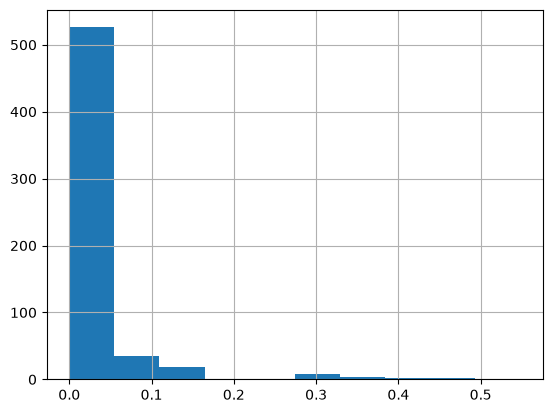

In [22]:
df_voisin0.distance.hist()

In [23]:
G = nx.from_pandas_edgelist(df_voisin, 'term_x', 'term_y', ['distance'])
nodes = df_voisin[["term_x"]].rename(columns={"term_x":"q45_clé"}).drop_duplicates().merge(df0[["q45_clé","labo","ufr","departement","research_fields","label_recherche_1","q11_quali_or_quanti","q10_type_data"]], on=["q45_clé"], how="left")
nodes

,q45_clé,labo,ufr,departement,research_fields,label_recherche_1,q11_quali_or_quanti,q10_type_data
0,2DRU-P3AV,paragraphe,mitsic,informatique,"['SH4', 'PE6']",Psychologie,Les deux,Données expérimentales ou d'observation;Donnée...
1,2JQN-P9PA,NaN,NaN,NaN,['SH4'],Psychologie,Les deux,Données expérimentales ou d'observation
2,2QNC-8AAQ,NaN,NaN,NaN,"['SH1', 'SH3', 'SH5', 'SH7']","Individus, normes, sociétés",Des données qualitatives,Données d'enquête;Données d'entretien;Données ...
3,2Y89-7BR9,transcrit,llce lea,NaN,"['SH4', 'SH5']",Psychologie,Des données qualitatives,Données d'entretien;Données textuelles ou docu...
4,32TW-JLY5,NaN,NaN,NaN,"['PE1', 'PE6', 'PE8', 'PE11']",Sciences informatiques,Les deux,Données expérimentales ou d'observation;Donnée...
...,...,...,...,...,...,...,...,...
114,YL4Q-KQAK,NaN,NaN,NaN,"['SH1', 'SH3', 'SH8']",Histoires de l'art et des sciences,Les deux,Données d'enquête;Données d'entretien;Données ...
115,YTMC-B4DP,paragraphe,NaN,ied,"['SH3', 'SH4']",Psychologie sociale,Les deux,Données expérimentales ou d'observation;Donnée...
116,ZB5S-ABHN,NaN,le,NaN,"['SH4', 'SH5']",Psychologie,Les deux,Données expérimentales ou d'observation;Donnée...
117,ZBFK-V8BA,NaN,NaN,NaN,['PE6'],Sciences informatiques,Les deux,Données expérimentales ou d'observation;Donnée...


In [24]:
#first compute the best partition
partition_1 = nx.community.louvain_communities(G, seed=111, resolution=1)
partition_2 = nx.community.louvain_communities(G, seed=111, resolution=2)
len(partition_1)

9

In [25]:
dict_partition_1 = {}
dict_partition_2 = {}

for n, part in enumerate(partition_1):
    for key in part:
        dict_partition_1[key] = n


for n, part in enumerate(partition_2):
    for key in part:
        dict_partition_2[key] = n

nodes["Label"] = nodes.q45_clé
nodes["partition_1"]= nodes.q45_clé.map(dict_partition_1.get)
nodes["partition_2"]= nodes.q45_clé.map(dict_partition_2.get)
node_attr = nodes.set_index('q45_clé').to_dict('index')
nx.set_node_attributes(G, node_attr)


In [35]:
!pip install jupyter_contrib_nbextensions

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.5/23.5 MB 2.7 MB/s  0:00:08 eta 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 4.4 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 5.1 MB/s  0:00:01 eta 0:00:01
  Created wheel for jupyter_contrib_nbextensions: filename=jupyter_contrib_nbextensions-0.7.0-py2.py3-none-any.whl size=23428843 sha256=8029a82676b78662f9941109c5806e079c2aaeb447beeb1e5e3339b3689410e9
  Stored in directory: /home/onyxia/.cache/pip/wheels/d9/79/80/be70fb5a8ce193c55b0238155c4c9122d87c96d93babb03204
  Created wheel for jupyter_contrib_core: filename=jupyter_contrib_core-0.4.2-py2.py3-none-any.whl size=17568 sha256=f6083ec39f268db11842f8fe50a2f9387c03cc3

In [36]:
from IPython.display import HTML

In [37]:
Sigma(G, node_size = G.degree, node_color = partition_1)

Sigma(nx.Graph with 119 nodes and 477 edges)

In [ ]:
df = pd.read_csv("../script_traitement/buparis8_chercheurs_besoins_accompagnement_7-24-2026_9_54.csv", sep =";")
df[["146. Clé", "143. Prénom", "142. Nom"]].loc[df["146. Clé"]=="82N2-HDNU"]

In [ ]:
for x in df["28. type_data"].loc[df["142. Nom"].isin(["Rieucau"])]:
    print(x)

In [ ]:
df_rf.loc[df_rf.q45_clé=="N99W-FKD9"]

## Labellisation "automatique" basée sur une forme e TF-IDF

$\text{TFIDF} = \text{TF} \times \text{IDF}$


$\text{TF} = \frac{\text{number of time term T appears in document D}}{\text{Total numbers of terms in document d}}$


$\text{IDF} = \frac{\text{Total number of documents D in corpus}}{\text{Numbers of documents containing term T}}$

$\text{TF} = \frac{\text{nOmbre de fois que le champ F de recherche apparaît dans le cluster C}}{\text{Nombre total de champs dans le cluster C}}$


$\text{IDF} = \frac{\text{Nombre total de cluster}}{\text{Nombre de cluster contenant le champ F}}$

In [ ]:
df_df["cluster"] = df_df.q45_clé.map(dict_partition_1)
dict_spec_fields = {}
i=-1
for c in df_df.cluster.unique():
    i+=1
    cl = df_df.loc[df_df.cluster==c]
    #print("####\n", len(cl))
    list_field_cluster = []
    for field in cl.variable.unique():
        champ_in_cl = len(cl.loc[cl.variable==field])
        
        cl_with_field = df_df.loc[df_df.variable==field].cluster.nunique()
        tf = champ_in_cl/len(cl)
        idf= np.log(df_df.cluster.nunique()/cl_with_field)
        list_field_cluster.append({"cluster":c, "q10_type_data":field,"tf_idf":tf*idf})
    df_f0 = pd.DataFrame.from_dict(list_field_cluster).sort_values("tf_idf", ascending=False)
    dict_spec_fields[c] = [research_fields for research_fields in df_f0.q10_type_data.head(3)]
    
    if i ==0:
        df_f = df_f0.copy()
    else:
        df_f = pd.concat([df_f, df_f0])



In [ ]:
no_cluster=8
no= nodes.loc[nodes.partition_1==no_cluster].merge(df[["146. Clé", "143. Prénom", "142. Nom"]].rename(columns={"146. Clé":"q45_clé"}), on=["q45_clé"], how="left")

dict_rf = {}
for key in no.q45_clé:
    rf = df_rf.loc[df_rf.q45_clé==key]
    #print(key)
    list_rf = []
    for x in rf.q10_type_data:
        #print(x)
        x_split = x.split(" ")[0]
        #print(x_split)
        list_rf.append(x_split)
    dict_rf[key]=list_rf

print(dict_spec_fields[no_cluster])
no["labels"] = no.partition_1.map(dict_spec_fields.get)
no

In [ ]:
dict_label_part_1 = {
    0:"Etudes expérimentale",
    1: "Données du web et statistiques",
    2: "Données statistiques et textutelles",
    3: "Données textuelles et observations",
    4: "Corpus textuels",
    5: "Entretiens",
    6: "Aucune",
    7: "Entretiens et enquêtes",
    8: "Données statistiques et observations"
}

In [ ]:
dict_rf = {}
for key in nodes.q45_clé:
    rf = df_rf.loc[df_rf.q45_clé==key]
    #print(key)
    list_rf = []
    for x in rf.q24_research_fields:
        #print(x)
        x_split = x.split(" ")[0]
        #print(x_split)
        list_rf.append(x_split)
    dict_rf[key]=list_rf

In [ ]:
nodes["clust_type_data"] = nodes.partition_1.map(dict_label_part_1.get)
nodes["auto_clust_data"] = nodes.partition_1.map(dict_spec_fields.get)


In [ ]:
nodes.loc[nodes.clust_type_data.isna()]

In [ ]:
df02 = df0.loc[~df0.q45_clé.isin(["Z37Y-6JGC","QNYZ-3MH2"])].merge(nodes[['q45_clé', 'clust_type_data', 'auto_clust_data']], on =["q45_clé"], how="left")
df02

In [ ]:
# on enregistre les nouvelles variables dans le dataframe original
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "w") as file_out:
    df02.to_csv(file_out, sep=",", index= False)

## 

In [ ]:
dic_new_var = {'name':"Style de données",
               'label':'clust_type_data',
               'group':'Type de données',
               'personal_data':False,
               'type':'simple_nominal',
               'opened_question':False,
               'type_panda':df02.clust_type_data.dtypes,
               'no_question':28,
               'question':"",
               'question_family':'',
               'comment':"Label donnés manuellement aux clusters de données"
              }
new_variable = pd.DataFrame.from_dict(data=[dic_new_var])
new_variable
df_col1 = pd.concat([df_col,new_variable], ignore_index = True))
df_col1

In [ ]:
dic_new_var = {'name':"Style de données",
               'label':'auto_clust_data',
               'group':'Type de données',
               'personal_data':False,
               'type':'simple_nominal',
               'opened_question':False,
               'type_panda':df02.auto_clust_data.dtypes,
               'no_question':28,
               'question':"",
               'question_family':'',
               'comment':"Label donnés automatiquement aux clusters de données avec un tf-idf"
              }
new_variable = pd.DataFrame.from_dict(data=[dic_new_var])
new_variable
df_col2 = pd.concat([df_col1,new_variable], ignore_index = True)
df_col2

In [ ]:
df_col2.to_csv("../le_questionnaire/dico_variable.csv", sep=",", index= False)